# 03 Emotion analysis

**Question:** How can readers prefer a mood among semantically relevant books? We estimate seven emotions from blurbs using a pretrained DistilRoBERTa classifier. This is more specific than positive/negative sentiment.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd() if (Path.cwd() / "book_recommender").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
import pandas as pd
from book_recommender.config import RAW, CLEAN, CLASSIFIED, ENRICHED, REPORTS


In [2]:
from book_recommender.config import EMOTIONS
from book_recommender.sentiment_analysis import description_chunks, score_emotions
books = pd.read_csv(CLASSIFIED, dtype={"isbn13": str, "book_id": str})
description_chunks(books.description.iloc[0])[:3]

['A NOVEL THAT READERS and critics have been eagerly anticipating for over a decade, Gilead is an astonishingly imagined story of remarkable lives.',
 'John Ames is a preacher, the son of a preacher and the grandson (both maternal and paternal) of preachers.',
 'It’s 1956 in Gilead, Iowa, towards the end of the Reverend Ames’s life, and he is absorbed in recording his family’s story, a legacy for the young son he will never see grow up.']

## Why split descriptions
A transformer has a token limit. Sentence chunks capped at 100 words let later parts of long blurbs contribute. A word cap is not a token guarantee, so token truncation is retained. This sentence splitter is intentionally simple and can mishandle abbreviations.

In [3]:
example = score_emotions(books.head(5), batch_size=4)
example[["title", *EMOTIONS, "dominant_emotion"]]

emotions: 0it [00:00, ?it/s]

emotions: 0it [00:00, ?it/s]

,title,anger,disgust,fear,joy,neutral,sadness,surprise,dominant_emotion
0,Gilead,0.007823,0.089079,0.151344,0.224548,0.245116,0.167134,0.114957,neutral
1,Spider's Web,0.097645,0.117150,0.164160,0.126171,0.415338,0.020082,0.059454,neutral
2,Rage of angels,0.023144,0.022589,0.527283,0.381676,0.030975,0.006448,0.007885,fear
3,The Four Loves,0.069881,0.103767,0.136981,0.102742,0.553873,0.023764,0.008990,neutral
4,The Problem of Pain,0.030412,0.124312,0.025810,0.042212,0.632335,0.132638,0.012281,neutral


## Aggregate chunk predictions
We average each emotion's probabilities across chunks, giving an overall description tone. Maximum pooling instead highlights isolated intense moments. Mean probabilities sum to approximately one; neither aggregation guarantees the tone of the full book.

<Axes: ylabel='title'>

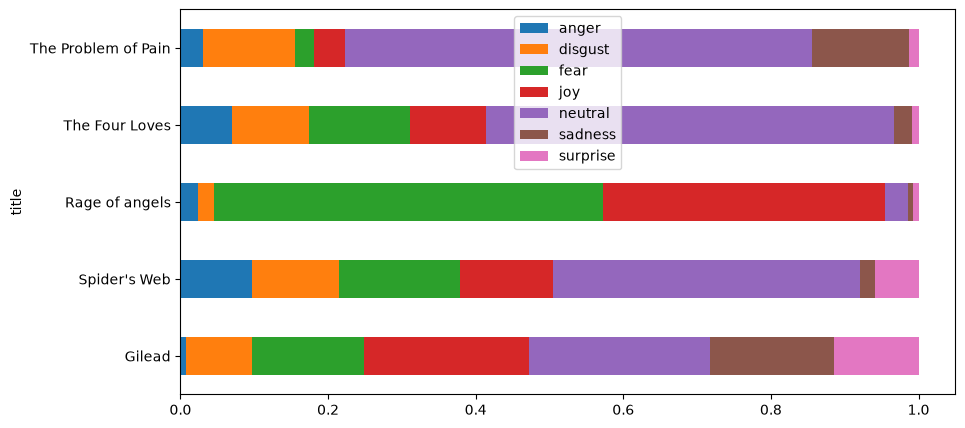

In [4]:
import numpy as np
assert np.allclose(example[list(EMOTIONS)].sum(axis=1), 1, atol=1e-5)
example.set_index("title")[list(EMOTIONS)].plot.barh(stacked=True, figsize=(10, 5))

## Prepare all scores
Run `python -m scripts.build_pipeline --stage emotions`. The dashboard uses Happy→joy, Sad→sadness, Suspenseful→fear, Surprising→surprise, Angry→anger, and Calm→neutral. Fear and neutral are imperfect proxies for suspense and calm.

In [5]:
if ENRICHED.exists():
    enriched = pd.read_csv(ENRICHED)
    display(enriched.dominant_emotion.value_counts().to_frame("books"))

,books
dominant_emotion,
neutral,3973
fear,555
disgust,389
joy,378
sadness,233
anger,132
surprise,69


## Reflection
Compare a cheerful blurb for a tragic story with a neutral factual description. Why might classifier probabilities disagree with a reader? Consider the effects of domain shift and marketing language.